<a href="https://colab.research.google.com/github/miskat-bcit/COMP-9170-Data-Science-Project/blob/Miskat/Fake_News_Preliminary_Experiment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Fake News Detection — Preliminary Experiment

## 1. Upload the dataset


In [ ]:
from pathlib import Path

if not (Path('Fake.csv').exists() and Path('True.csv').exists()):
    from google.colab import files
    print('Upload Fake.csv and True.csv')
    files.upload()

assert Path('Fake.csv').exists() and Path('True.csv').exists(), 'Both CSV files are required.'

Upload Fake.csv and True.csv


Saving Fake.csv to Fake.csv
Saving True.csv to True.csv


## 2. Import libraries and load data

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

fake = pd.read_csv('Fake.csv')
real = pd.read_csv('True.csv')
print('Fake articles:', len(fake))
print('Real articles:', len(real))
print('Columns:', list(fake.columns))
print('Missing cells (fake):', int(fake.isna().sum().sum()))
print('Missing cells (real):', int(real.isna().sum().sum()))
print('Duplicate title-and-text pairs (fake):', int(fake.duplicated(['title','text']).sum()))
print('Duplicate title-and-text pairs (real):', int(real.duplicated(['title','text']).sum()))

Fake articles: 23481
Real articles: 21417
Columns: ['title', 'text', 'subject', 'date']
Missing cells (fake): 0
Missing cells (real): 0
Duplicate title-and-text pairs (fake): 5573
Duplicate title-and-text pairs (real): 220


## 3. Combine the datasets and remove exact duplicates

Use **0 = fake** and **1 = real**. We remove repeated title-and-text pairs before splitting, so the same exact article is not repeated across training and testing.

In [ ]:
fake['label'] = 0
real['label'] = 1

df = pd.concat([fake, real], ignore_index=True)
df = df.drop_duplicates(subset=['title', 'text']).copy()
df['text'] = df['text'].fillna('')
print('Articles after exact duplicate removal:', len(df))
print(df['label'].value_counts().rename(index={0:'Fake',1:'Real'}))
print('Subject categories by label:')
print(pd.crosstab(df['subject'], df['label']).rename(columns={0:'Fake',1:'Real'}))

Articles after exact duplicate removal: 39105
label
Real    21197
Fake    17908
Name: count, dtype: int64
Subject categories by label:
label            Fake   Real
subject                     
Government News   532      0
News             9050      0
US_News           783      0
left-news         705      0
politics         6838      0
politicsNews        0  11217
worldnews           0   9980


## 4. Simple exploratory analysis

         count   mean    std  min    25%    50%    75%     max
label                                                         
Fake   17908.0  414.7  357.0  0.0  264.0  371.0  499.0  8135.0
Real   21197.0  384.9  273.8  0.0  147.0  359.0  523.0  5172.0


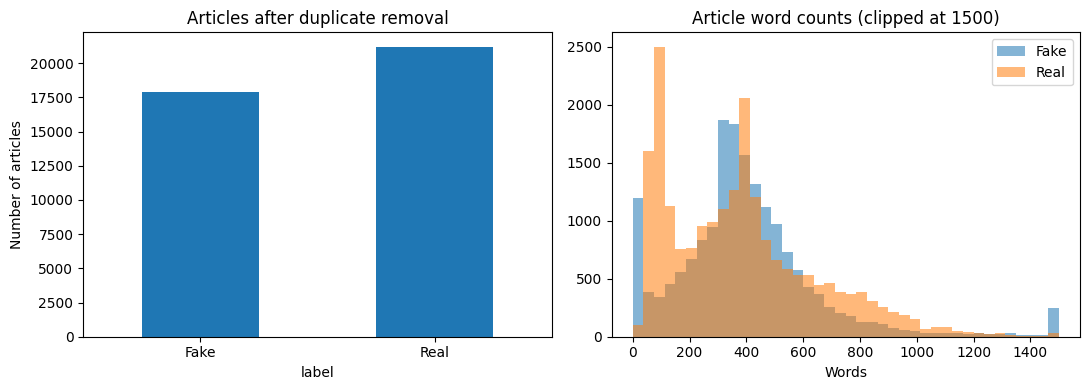

In [ ]:
df['word_count'] = df['text'].str.split().str.len()
print(df.groupby('label')['word_count'].describe().rename(index={0:'Fake',1:'Real'}).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
df['label'].map({0:'Fake',1:'Real'}).value_counts().reindex(['Fake','Real']).plot.bar(ax=axes[0])
axes[0].set_title('Articles after duplicate removal')
axes[0].set_ylabel('Number of articles')
axes[0].tick_params(axis='x', rotation=0)
for label, group in df.groupby('label'):
    axes[1].hist(group['word_count'].clip(upper=1500), bins=40, alpha=.55, label={0:'Fake',1:'Real'}[label])
axes[1].set_title('Article word counts (clipped at 1500)')
axes[1].set_xlabel('Words')
axes[1].legend()
plt.tight_layout()
plt.show()

## 5. Train/test split and TF-IDF

Use only the **article text** for the models. Fit TF-IDF on training articles only to avoid leakage from test articles.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    df['text'], df['label'], test_size=0.20,
    random_state=42, stratify=df['label']
)
print('Training articles:', len(X_train))
print('Testing articles:', len(X_test))

tfidf = TfidfVectorizer(stop_words='english', max_features=20000)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)
print('TF-IDF training matrix:', X_train_tfidf.shape)

Training articles: 31284
Testing articles: 7821
TF-IDF training matrix: (31284, 20000)


## 6. Train Naive Bayes and Logistic Regression

In [ ]:
models = {
    'Naive Bayes': MultinomialNB(),
    'Logistic Regression': LogisticRegression(max_iter=1000)
}
results = []
predictions = {}
for name, model in models.items():
    model.fit(X_train_tfidf, y_train)
    pred = model.predict(X_test_tfidf)
    predictions[name] = pred
    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, pred),
        'Precision (real)': precision_score(y_test, pred, pos_label=1),
        'Recall (real)': recall_score(y_test, pred, pos_label=1),
        'F1 (real)': f1_score(y_test, pred, pos_label=1)
    })

results_df = pd.DataFrame(results).set_index('Model')
print('All values are proportions; multiply by 100 for percentages.')
print(results_df.round(4).to_string())
print('Percentages for proposal:')
print((results_df * 100).round(2).to_string())

All values are proportions; multiply by 100 for percentages.
                     Accuracy  Precision (real)  Recall (real)  F1 (real)
Model                                                                    
Naive Bayes            0.9257            0.9203         0.9448     0.9324
Logistic Regression    0.9856            0.9816         0.9920     0.9867
Percentages for proposal:
                     Accuracy  Precision (real)  Recall (real)  F1 (real)
Model                                                                    
Naive Bayes             92.57             92.03          94.48      93.24
Logistic Regression     98.56             98.16          99.20      98.67


## 7. Confusion matrices and classification reports

 Naive Bayes
              precision    recall  f1-score   support

        Fake       0.93      0.90      0.92      3582
        Real       0.92      0.94      0.93      4239

    accuracy                           0.93      7821
   macro avg       0.93      0.92      0.92      7821
weighted avg       0.93      0.93      0.93      7821



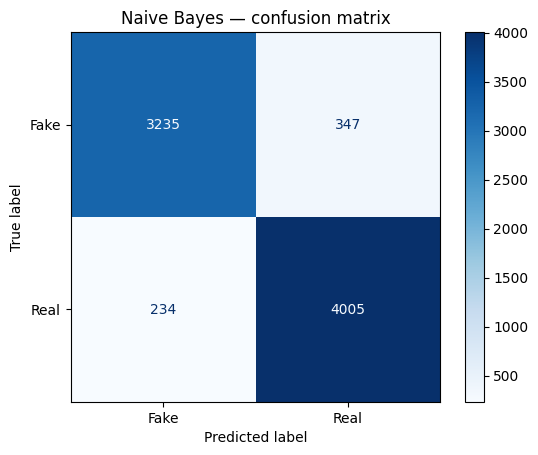

 Logistic Regression
              precision    recall  f1-score   support

        Fake       0.99      0.98      0.98      3582
        Real       0.98      0.99      0.99      4239

    accuracy                           0.99      7821
   macro avg       0.99      0.98      0.99      7821
weighted avg       0.99      0.99      0.99      7821



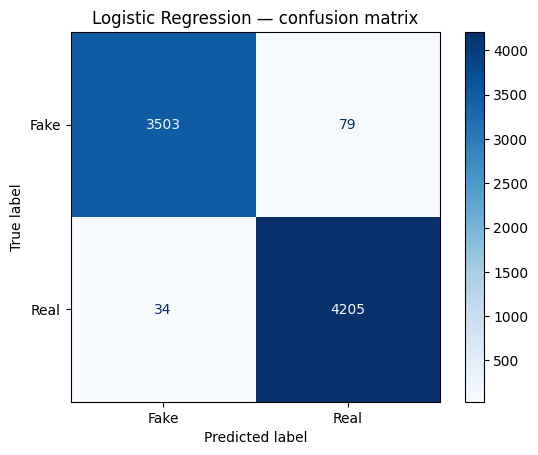

In [ ]:
for name, pred in predictions.items():
    print('', name)
    print(classification_report(y_test, pred, target_names=['Fake', 'Real']))
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=['Fake', 'Real'], cmap='Blues'
    )
    plt.title(name + ' — confusion matrix')
    plt.show()

## 8. Interpret the results

The proposal reports approximately **92.58% accuracy / 93.25% real-class F1** for Naive Bayes and **98.54% accuracy / 98.66% real-class F1** for Logistic Regression. Small differences in installed library versions may occur.

**Caution:** These are scores on a random split of this particular dataset, **not verified factuality or media trustworthiness**. The fake and real collections have different topic/source patterns, and near-duplicates may remain even after exact duplicate removal. Credibility-score calibration and cross-topic/source evaluation are planned for the full project, not completed in this preliminary experiment.